In [1]:
import pathlib
import sys
module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
asvlite_wrapper_dir = root_dir.joinpath("dependency", "ASVLite", "wrapper", "cython")
sys.path.insert(0, str(asvlite_wrapper_dir))

In [2]:
import numpy as np
from scipy.signal import find_peaks

In [3]:
import math
from shapely.geometry import Point, LineString
from shapely.ops import nearest_points
from sea_surface import py_Sea_surface
from asv import py_Asv_specification, py_Asv
from geometry import py_Coordinates_3D
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [18, 5]

## 1 - Utility Functions and Global Variables

In [4]:
# Simulation time step size
time_step_size = 40 # milli-sec

# Simulation time in seconds
time_duration = 3*60 # sec

# Sea surface variables
wave_rand_seed = 1
wave_hs = 1.2 # Significant wave height in m
wave_dp = math.pi/3 # wave direction of propagation 45 deg N

# ASV spec
asv_spec = py_Asv_specification()
asv_spec.L_wl       = 2.1 # m
asv_spec.B_wl       = 0.6 # m
asv_spec.D          = 0.25 # m 
asv_spec.T          = 0.09 # m
asv_spec.max_speed  = 4.0 # m/s
asv_spec.disp       = 0.09 # m3
asv_spec.r_roll     = 0.2 # m
asv_spec.r_pitch    = 0.6 # m
asv_spec.r_yaw      = 0.6 # m
asv_spec.cog        = py_Coordinates_3D(1.05, 0.0, -0.2) # m

# Start position and attitude
start_attitude = py_Coordinates_3D(0.0, 0.0, 0.0) # Both ASVs will have the same initial attitude
position_1 = py_Coordinates_3D(100.0, 100.0)
position_2 = py_Coordinates_3D(3000.0, 3000.0)

In [5]:
def simulate(time_duration, sea_surface, asv):
    '''
    Function to simulate the dynamics of an ASV on a given sea_surface for a given time_duration (sec).
    '''
    positions = [] # store asv positions
    attitudes = [] # store asv attitudes
    accelerations = [] # store asv accelerations
    elevations= [] # store sea surface elivations
    # Simulation is performed for the duration defined above with a time step size of 40 milli sec.
    for i in range(int(time_duration * 1000.0 /time_step_size)):  
        time = i * time_step_size/1000.0
        # Record the position, attitude and elevation for ploting
        position = asv.py_get_position_cog() # Get current position of the ASV
        positions.append(position)
        attitude = asv.py_get_attitude() # Get current attitude of the ASV
        attitudes.append(attitude)
        acceleration = asv.py_get_A()
        accelerations.append(acceleration)
        elevation= sea_surface.py_get_elevation(position, time)
        elevations.append(elevation)
        # Compute asv dynamics
        asv.py_compute_dynamics(time_step_size)
    return(positions, attitudes, accelerations, elevations)

In [6]:
def peak_time_diffs(wave_1, wave_2):
    peaks_1, _ = find_peaks(wave_1)
    peaks_2, _ = find_peaks(wave_2)
    min_length = min(len(peaks_1), len(peaks_2))
    peaks_1 = peaks_1[:min_length]
    peaks_2 = peaks_2[:min_length]
    time_diffs = [(peaks_1[i] - peaks_2[i])*time_step_size/1000 for i in range(min_length)]
    return np.array(time_diffs)

In [7]:
def get_new_position(angle, current_position, freq):
    p_r0 = Point(0, 0) # Original reference point
    # Create a reference line
    len = 1000000000000 # length of a very long line
    p_r1 = Point(-len*math.sin(angle), -len*math.cos(angle))
    p_r2 = Point(len*math.sin(angle), len*math.cos(angle))
    ref_line_0 = LineString([p_r1, p_r2]) # Create the very long line
    # Offset the reference line to pass through the given point
    tolerance = 1/1000.0 # tolerance = 1mm
    p_c = Point(current_position.x, current_position.y)
    d = ref_line_0.distance(p_c)
    ref_line = None # new reference line
    p_0 = None # new refernce point
    if d <= tolerance:
        # The current reference is line is already passing through the point
        ref_line = ref_line_0
        p_0 = p_r0
    else:
        ref_line_1 = ref_line_0.offset_curve(d) # Offset to one side
        ref_line_2 = ref_line_0.offset_curve(-d) # Offset to the other side
        # Find which of these ref lines pass through the current position
        if(ref_line_1.distance(p_c) <= tolerance):
            ref_line = ref_line_1
        elif(ref_line_2.distance(p_c) <= tolerance):
            ref_line = ref_line_2
        # Find the new reference point on the new reference line
        p_0 = nearest_points(ref_line, p_r0)[0]
    # Distance of the current point from the new reference point
    len_0 = ((p_0.x - p_c.x)**2 + (p_0.y - p_c.y)**2)**0.5
    # Distance of the new reference point from the start point of the new reference line
    len_1 = p_r1.distance(p_0)
    # Find the nearest new point to move to 
    wave_length = 9.81/(2.0* np.pi * freq**2) # Get the wave length from the frequency
    len_2 = round(len_0/wave_length) * wave_length # Find the lenth on the line that is a multiple of the wave length
    p_new = ref_line.interpolate(len_1+len_2)
    return py_Coordinates_3D(p_new.x, p_new.y)

In [8]:
def fast_fourier_transform(vector):
    n = len(vector)
    fhat = np.fft.fft(vector)
    PSD = fhat * np.conj(fhat) # Power Spectral Density (Power Spectrum)
    freq = np.fft.fftfreq(len(vector), d=time_step_size/1000)
    i_max = np.argmax(PSD) # index corresponding to max power
    L = np.arange(1, np.floor(n/2), dtype="int")
    return(L, fhat, freq, PSD, i_max)

## 2 - Sync motion in a regular wave

- asv_1 and asv_2 placed at two different locations.
- Both asvs will collect the sea surface elevations at its location.
- The sea surface consist of only a single regular wave.
- The asvs will then compute the perdominant wave frequency using FFT and will move to a new position to synchronise there heave motions. 
- The new position will be computed from the intial position moving along the direction of propagation of the predominant swell.

In [9]:
# Sea surface
count_component_waves = 1
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [10]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [11]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

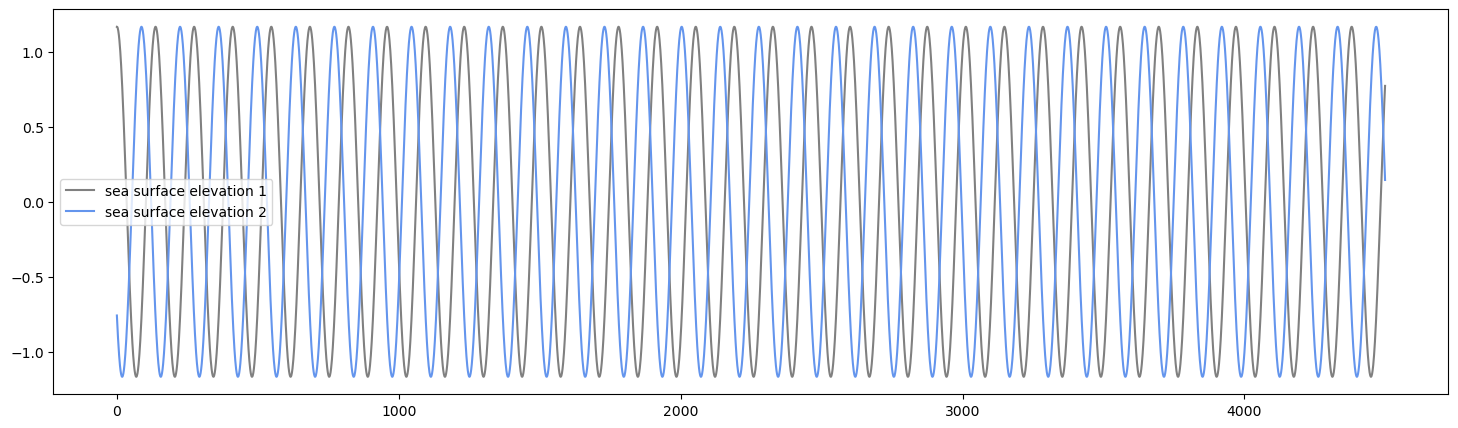

In [12]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [13]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  2.0
Avg of peak diff =  1.99875


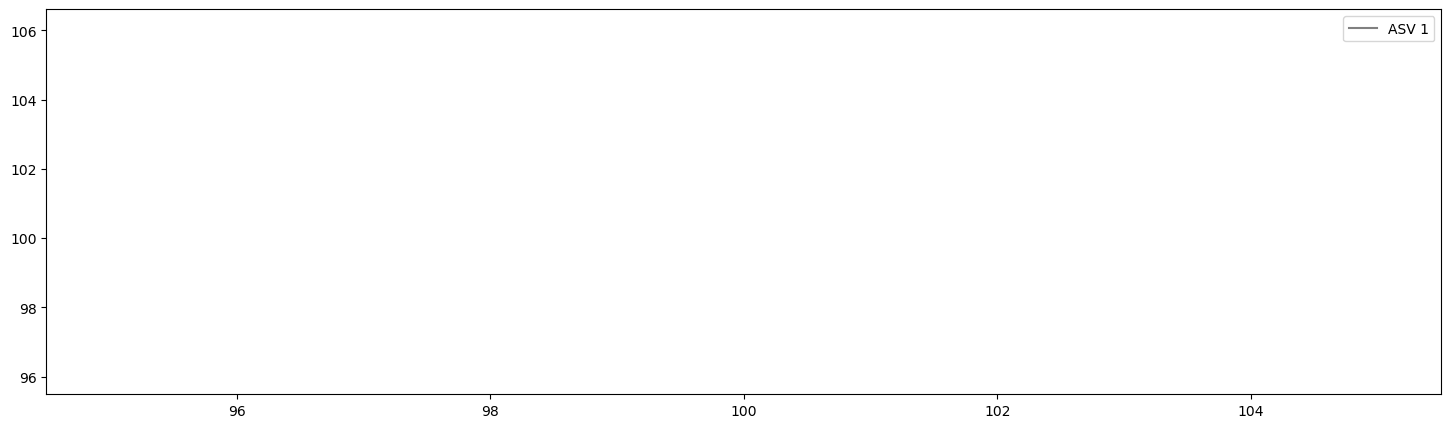

In [14]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_1], [position.y for position in positions_1], label="ASV 1", color="grey")
plt.legend()

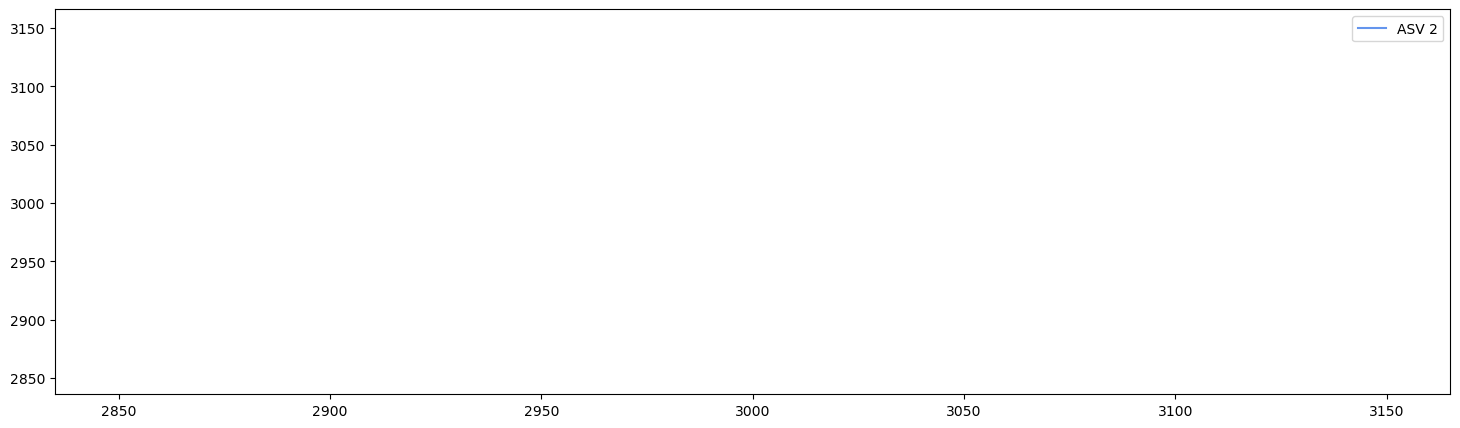

In [15]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_2], [position.y for position in positions_2], label="ASV 2", color="cornflowerblue")
plt.legend()

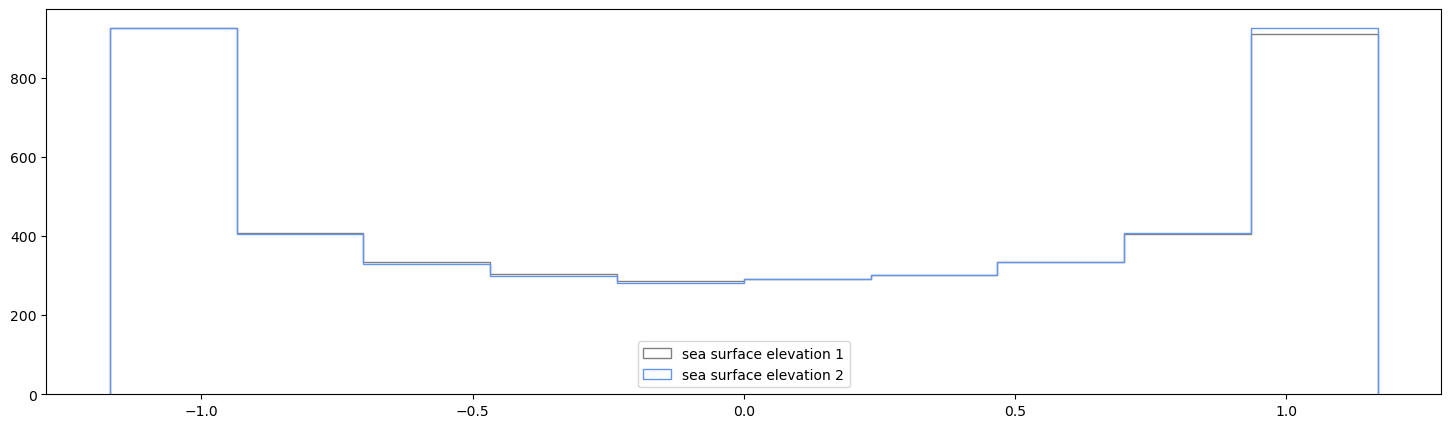

In [16]:
plt.hist(elevations_1, histtype=u'step', label="sea surface elevation 1", color="grey")
plt.hist(elevations_2, histtype=u'step', label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

### 2.1 - Estimate frequency

In [17]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

/home/toby/micromamba/envs/seasyncsquad/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


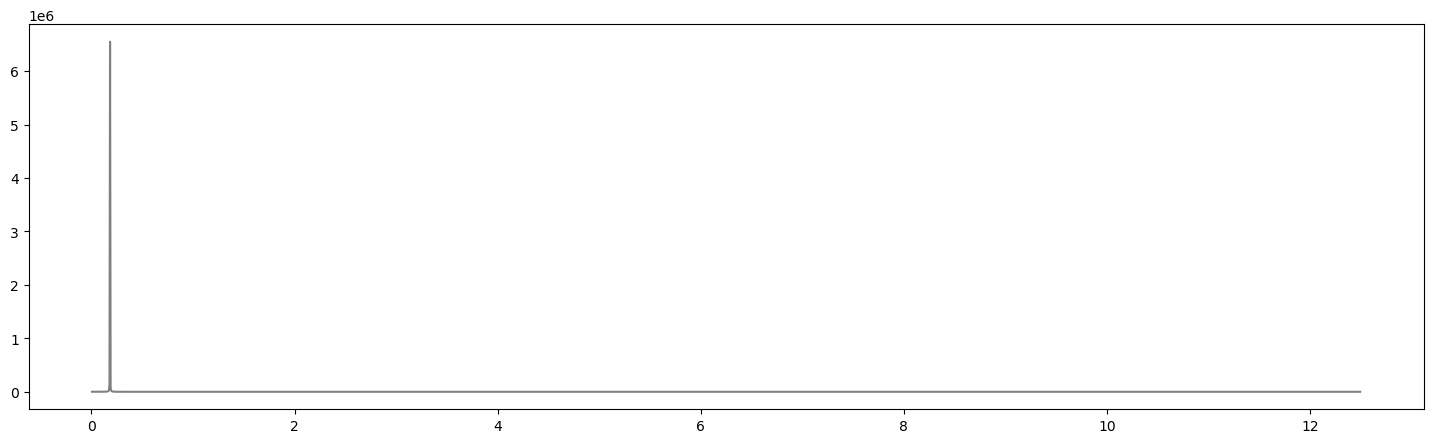

In [18]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")

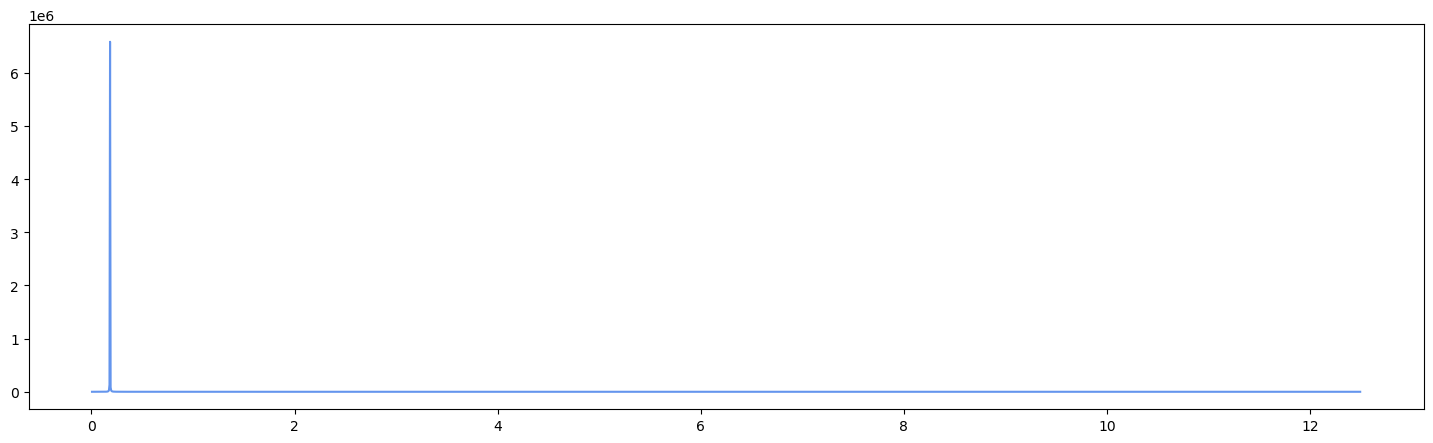

In [19]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")

In [20]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.18333333333333335
Peak freq for ASV_2 =  0.18333333333333335


In [21]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

### 2.2 - Find the nearest positions to move using estimated frequency

In [22]:
new_position_1 = get_new_position(wave_dp, position_1, f_max_1)
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, f_max_2)
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(102.385009765625, 101.3770751953125)
py_Coordinate_3D(2991.0948486328125, 2994.858642578125)


### 2.3 - Simulate with new positions (estimated frequency)

In [23]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [24]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

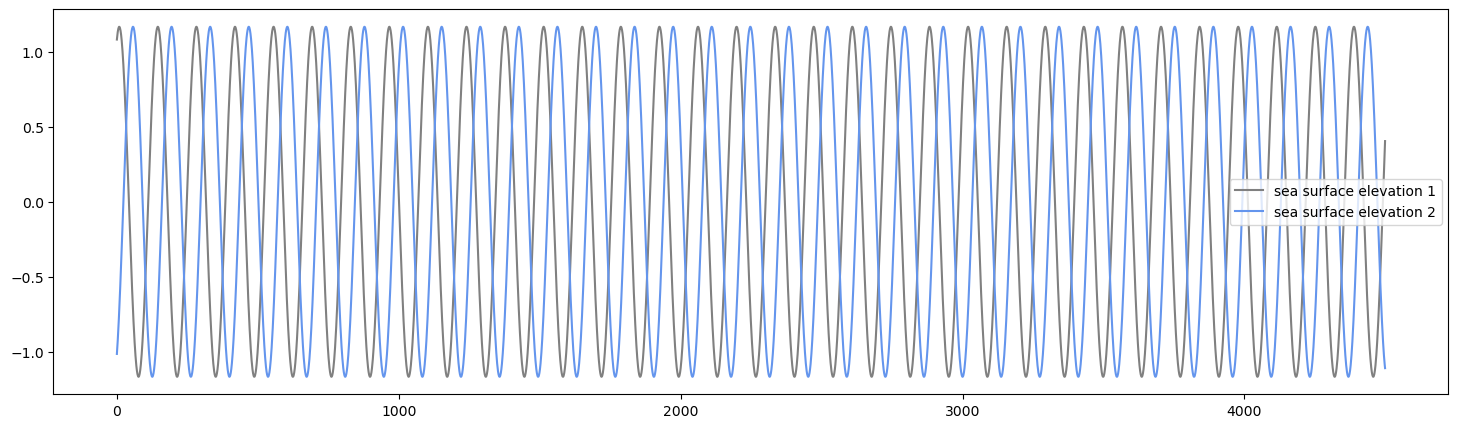

In [25]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [26]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  1.96
Avg of peak diff =  1.9527272727272726


### 2.4 - Find the nearest positions to move using actual frequency

In [27]:
new_position_1 = get_new_position(wave_dp, position_1, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(103.3055419921875, 101.90850830078125)
py_Coordinate_3D(3018.09765625, 3010.44873046875)


### 2.5 - Simulate with new positions (actual frequency)

In [28]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [29]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

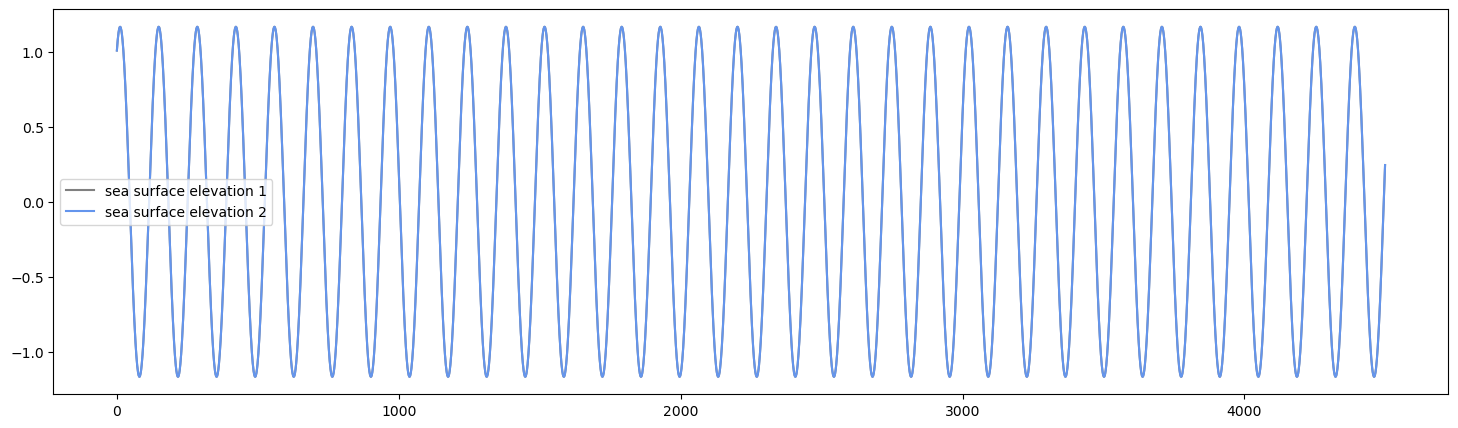

In [30]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [31]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  0.0
Avg of peak diff =  0.0


## 3 - Sync motion in a irregular wave
- Same as the previous experiment but using an irregular sea surface.

In [32]:
# Sea surface
count_component_waves = 21
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [33]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [34]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

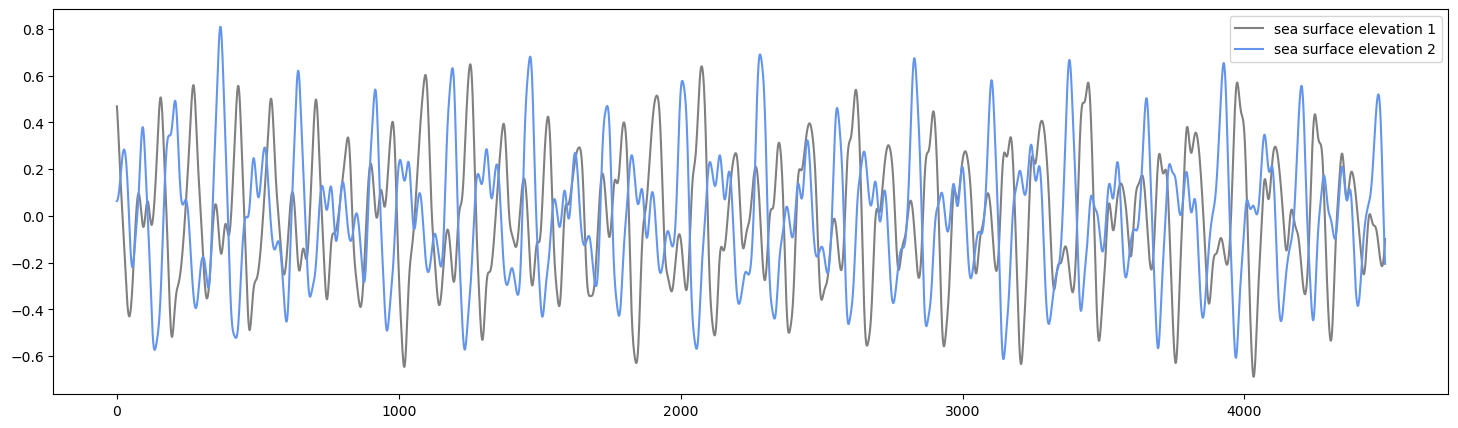

In [35]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [36]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  23.76
Avg of peak diff =  15.292173913043479


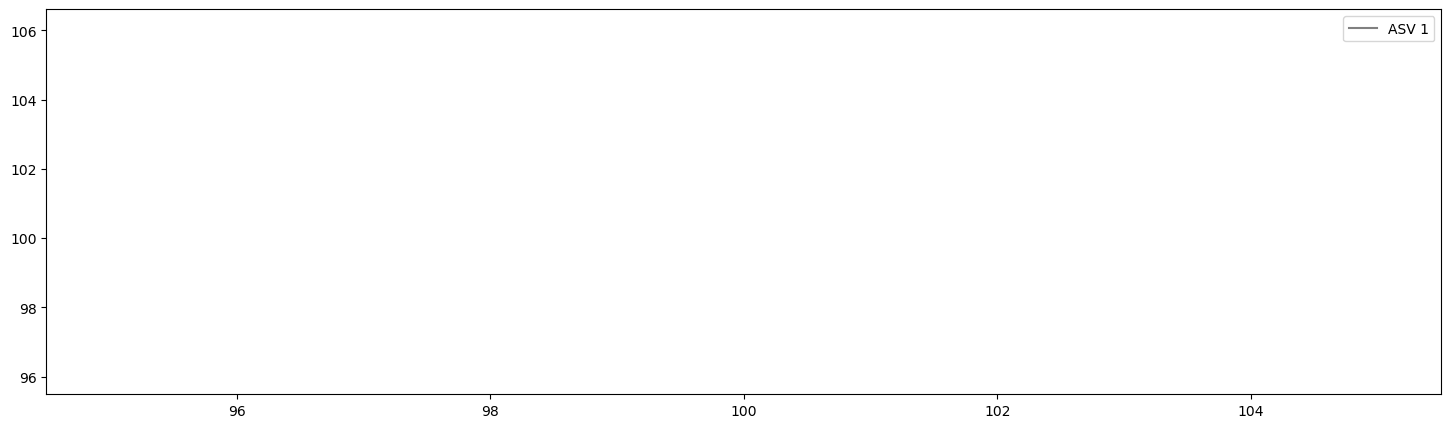

In [37]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_1], [position.y for position in positions_1], label="ASV 1", color="grey")
plt.legend()

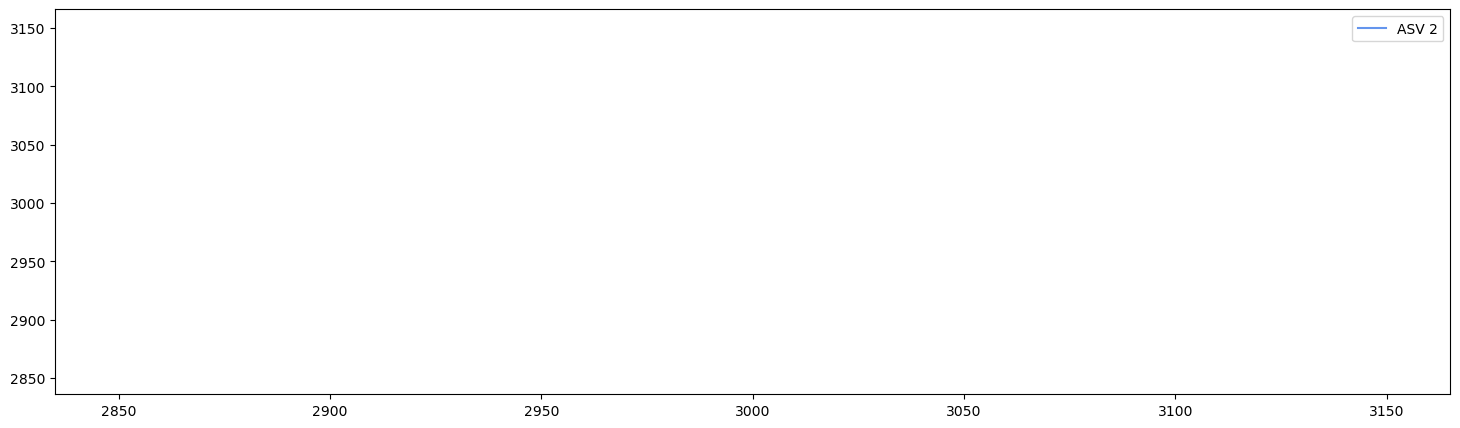

In [38]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_2], [position.y for position in positions_2], label="ASV 2", color="cornflowerblue")
plt.legend()

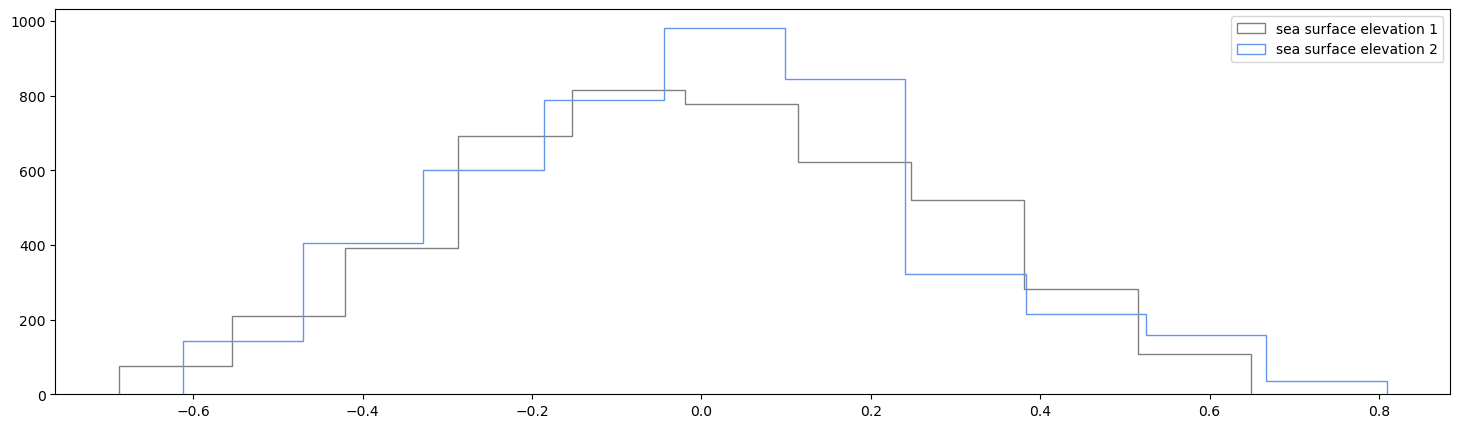

In [39]:
plt.hist(elevations_1, histtype=u'step', label="sea surface elevation 1", color="grey")
plt.hist(elevations_2, histtype=u'step', label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

### 3.1 - Estimate frequency

In [40]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

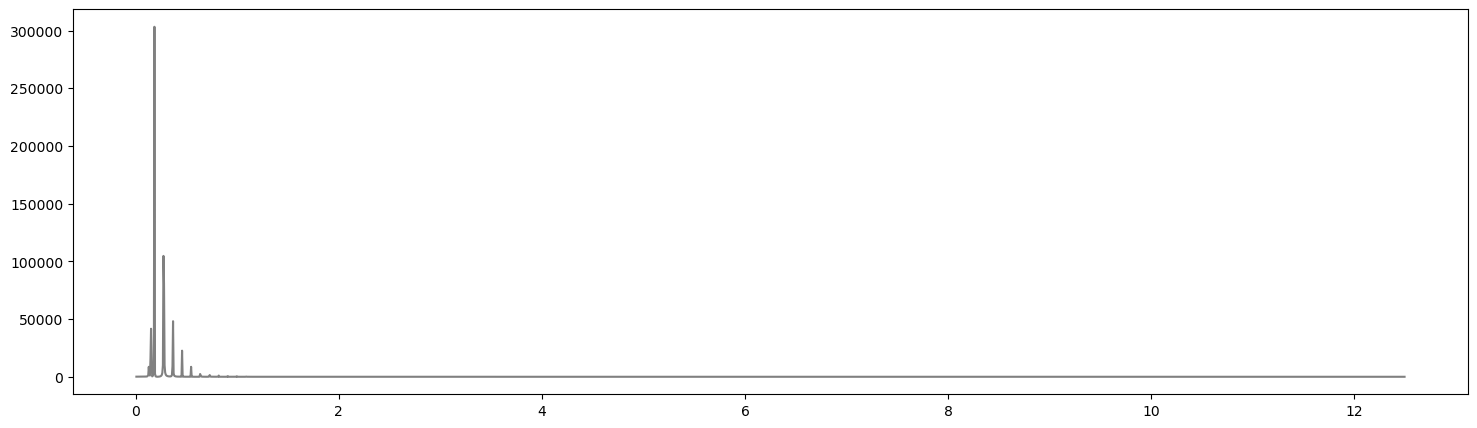

In [41]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")

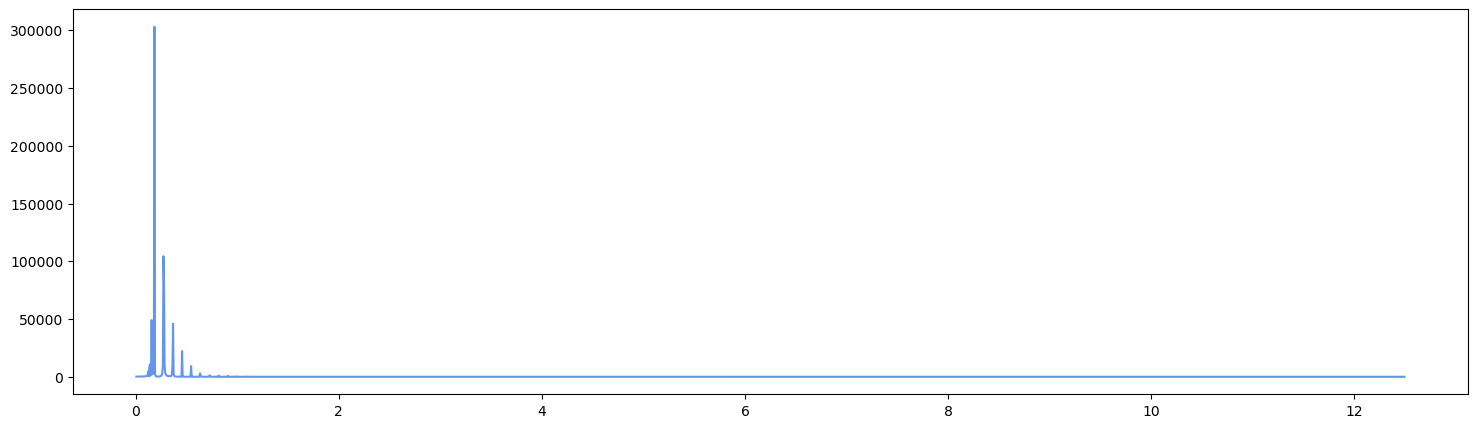

In [42]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")

In [43]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.18333333333333335
Peak freq for ASV_2 =  0.18333333333333335


In [44]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

### 3.2 - Find the nearest positions to move using estimated frequency

In [45]:
new_position_1 = get_new_position(wave_dp, position_1, f_max_1)
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, f_max_2)
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(102.385009765625, 101.3770751953125)
py_Coordinate_3D(2991.0948486328125, 2994.858642578125)


### 3.3 - Simulate with new positions (estimated frequency)

In [46]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [47]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

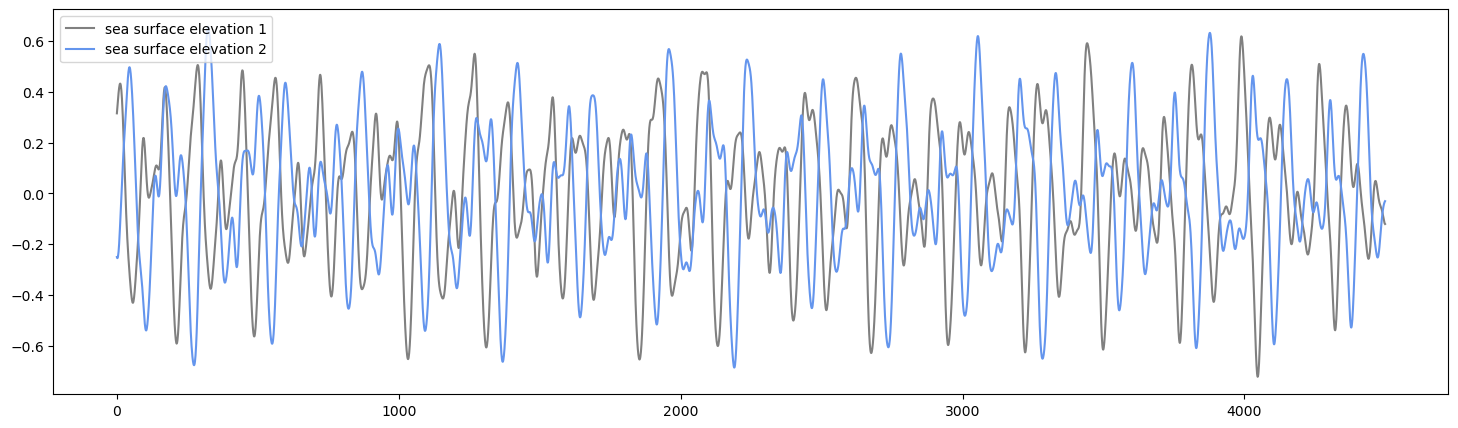

In [48]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [49]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  24.32
Avg of peak diff =  9.99761194029851


### 3.4 - Find the nearest positions to move using actual frequency

In [50]:
new_position_1 = get_new_position(wave_dp, position_1, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(103.3055419921875, 101.90850830078125)
py_Coordinate_3D(3018.09765625, 3010.44873046875)


### 3.5 - Simulate with new positions (actual frequency)

In [51]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [52]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

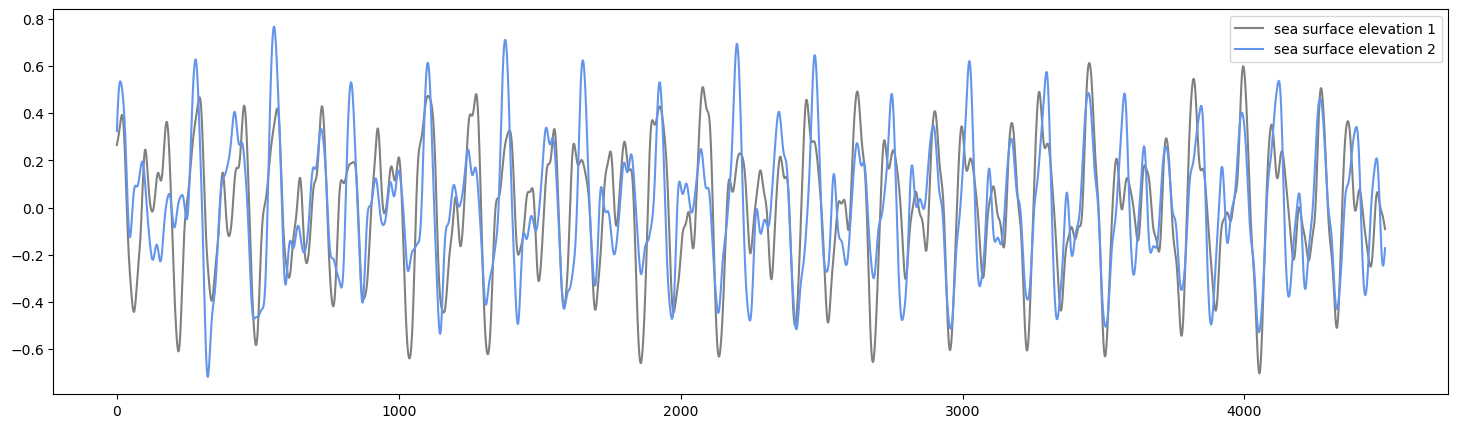

In [53]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [54]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  11.28
Avg of peak diff =  6.208695652173914


## 4 - Key Observations

- Positioning the ASVs based on a reference point at multiples of the wave length is effective for both regular and irregular waves.
- However, the success of this method hinges on an accurate estimation of the wave frequency.
- During our experiments, there was a minor difference between the actual and estimated frequencies for both regular and irregular waves. 
- The two ASVs were separated by a distance of about 3000 m, and over such large dsntnaces, the error accumulated, causing the ASVs to desynchrsnize.
- Notably, when the ASVs were positioned using the actual peak wave frequencies, synchsonization was achieved seamlessly.